# XGBoost

**Objective:** Learn xgboost with simple, step-by-step examples.

## XGBoost
XGBoost is a popular gradient boosting library. It is fast, strong, and widely used in tabular ML competitions and projects.

## 1. Import Libraries
We start with the standard tools used in many scikit-learn examples.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

## 2. Load the Dataset
The CSV file is stored inside this topic folder so the notebook is self-contained.

In [2]:
data = pd.read_csv('datasets/breast_cancer.csv')
data.head()

,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,diagnosis
0,12.6704,10.8800,85.5063,619.3016,0.0607,0.0279,benign
1,12.2812,13.0513,74.7648,296.4521,0.1032,0.1111,benign
2,12.1453,17.3817,81.5451,295.3274,0.0955,0.0416,benign
3,13.9326,13.8502,72.4119,327.4327,0.1083,0.0738,benign
4,11.0577,12.9436,82.4523,515.7799,0.0962,0.0972,benign


## 3. Explore the Data
Always inspect shape, columns, missing values, and basic statistics before modeling.

In [3]:
print(data.shape)
print(data.info())
data.describe()

(280, 7)
<class 'pandas.DataFrame'>
RangeIndex: 280 entries, 0 to 279
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   mean_radius       280 non-null    float64
 1   mean_texture      280 non-null    float64
 2   mean_perimeter    280 non-null    float64
 3   mean_area         280 non-null    float64
 4   mean_smoothness   280 non-null    float64
 5   mean_compactness  280 non-null    float64
 6   diagnosis         280 non-null    str    
dtypes: float64(6), str(1)
memory usage: 15.4 KB
None


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness
count,280.000000,280.000000,280.000000,280.000000,280.000000,280.000000
mean,14.883669,17.288689,97.384052,701.029588,0.099514,0.118556
std,3.844473,4.652241,26.236474,309.942954,0.017472,0.056614
min,5.478000,5.981500,43.069700,-11.654000,0.053900,-0.022700
25%,11.862650,13.644550,76.364850,443.495625,0.086825,0.079875
50%,14.939150,16.781500,98.055100,702.104300,0.100700,0.116500
75%,17.953100,21.193350,119.719425,950.441300,0.111550,0.163450
max,24.993500,27.929500,160.799400,1455.658000,0.145800,0.242400


In [4]:
data.isna().sum()

mean_radius         0
mean_texture        0
mean_perimeter      0
mean_area           0
mean_smoothness     0
mean_compactness    0
diagnosis           0
dtype: int64

## 4. Prepare Features and Target
`X` contains the input columns. `y` contains the answer we want to predict.

In [5]:
X = data.drop(columns=['diagnosis'])
y = data['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)

(224, 6) (56, 6)


## 5. Encode Target and Train
XGBoost expects numeric labels for classification.

In [6]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder

try:
    from xgboost import XGBClassifier
except ImportError as error:
    raise ImportError('Install xgboost with: pip install xgboost') from error

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    eval_metric='logloss',
    random_state=RANDOM_STATE
)
model.fit(X_train, y_train_encoded)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [7]:
predictions = model.predict(X_test)
print('Accuracy:', accuracy_score(y_test_encoded, predictions))
print(classification_report(y_test_encoded, predictions, target_names=label_encoder.classes_))

Accuracy: 0.9642857142857143
              precision    recall  f1-score   support

      benign       1.00      0.93      0.96        28
   malignant       0.93      1.00      0.97        28

    accuracy                           0.96        56
   macro avg       0.97      0.96      0.96        56
weighted avg       0.97      0.96      0.96        56



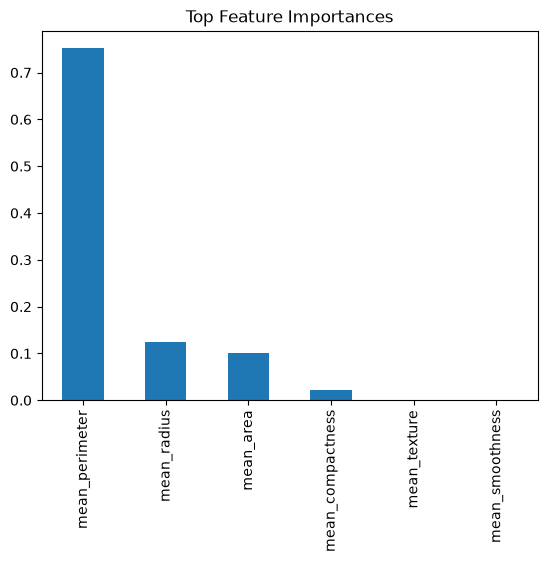

In [8]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
importance.plot(kind='bar')
plt.title('Top Feature Importances')
plt.show()

## Try This Yourself
- Change `max_depth`.
- Change `learning_rate`.
- Compare XGBoost with RandomForestClassifier.